In [1]:
import matplotlib.pyplot as plt
%load_ext autoreload
%autoreload 2

In [2]:
from models.mm_mode_independent_model import MarkovModeIndependentModel
from priors.alpha_prior import get_d2g_alpha
from priors.transition_prior import TransitionPrior
import pymc as pm
import models.model_utils as u

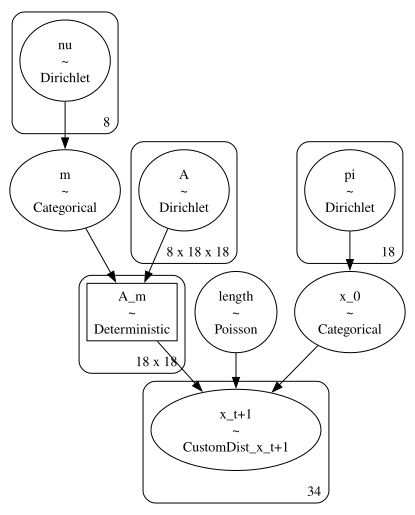

In [3]:
model = MarkovModeIndependentModel()
model.alpha = get_d2g_alpha(model.V)

beta = TransitionPrior(model.V)

beta.prefer_small_intervals(5,1)
beta.prefer_low_register(1,2,2)
beta.penalize_repeated_notes(0.3)
beta.offset(2)
model.beta = beta.get_beta()
model.build_model()
pm.model_to_graphviz(model.model)

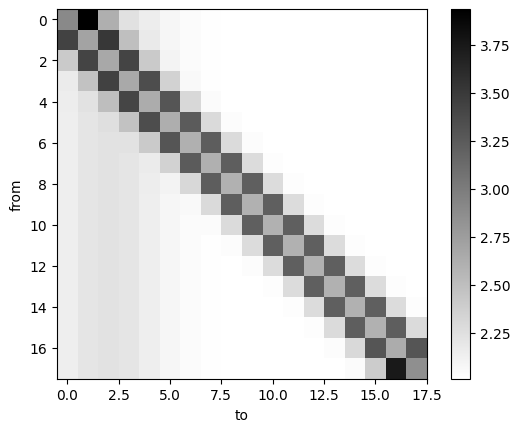

In [4]:
import models.model_utils as u
u.plot_heatmap(model.beta)

In [5]:
#samples = m2.prior_predict(1)
#m2.show_melody(samples[0])

In [6]:
#samples

In [7]:
#import models.model_utils as u

#u.plot_heatmap(samples[0]["A_0"].sel(chain=0,draw=0).to_numpy())


In [8]:

#u.plot_heatmap(samples[0]["A_m"].sel(chain=0,draw=0).to_numpy())

In [ ]:
import data.GradualePipeline as gp
data = gp.GradualePipeline.load("data/processed/dataset_pitches_modes.pkl")
data 

In [ ]:
trace = model.fit(
        data,
        draws=3000,
        tune=1000,
        description="init",
        use_latest=True
    )

In [ ]:
pm.model_to_graphviz(model.model)

In [ ]:

u.plot_heatmap(model.beta)
print(model.alpha)

In [ ]:
import arviz as az
az.plot_trace(trace, compact=True);

In [ ]:
az.plot_energy(trace);

In [ ]:
from analysis.visualise_posterior import plot_mode_heatmaps


In [ ]:
plot_mode_heatmaps(model.trace, "A")